## Kurs Pfade einpflegen

In [1]:
# Ziel: Das vollständige Kurs-Repository für Daten, Modelle und Hilfsdateien verfügbar machen.
from pathlib import Path
import os

DRIVE_FOLDER = "DeepLearningKurs"  # Ordnername unter "Meine Ablage" in Google Drive

try:
    # Dieser Import ist nur in Google Colab verfügbar.
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    # Google Drive einbinden und den dort abgelegten Repository-Ordner verwenden.
    drive.mount("/content/drive")
    repository_root = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    # Lokal vom aktuellen Ordner aus nach den eindeutigen Repository-Merkmalen suchen.
    search_locations = (Path.cwd(), *Path.cwd().parents)
    repository_root = next(
        (
            folder
            for folder in search_locations
            if (folder / "requirements.txt").is_file()
            and (folder / "notebooks").is_dir()
        ),
        None,
    )

if repository_root is None or not repository_root.is_dir():
    raise FileNotFoundError(
        "Das Kurs-Repository wurde nicht gefunden. Laden Sie den vollständigen Ordner "
        "'DeepLearningKurs' nach 'Meine Ablage' hoch oder passen Sie DRIVE_FOLDER an."
    )

# Relative Pfade funktionieren ab hier in allen Kursnotebooks identisch.
os.chdir(repository_root)
print("Kurs-Repository eingebunden; relative Pfade sind einsatzbereit.")


Kurs-Repository eingebunden; relative Pfade sind einsatzbereit.


In [2]:
import os
import sys

# Korrekten Zielpfad setzen
target_dir = r"C:\Users\mgach\Documents\DeepLearningKurs-main\notebooks\Project"

if os.path.exists(target_dir):
    os.chdir(target_dir)
    if target_dir not in sys.path:
        sys.path.append(target_dir)
    print("Arbeitsverzeichnis erfolgreich gewechselt zu:")
    print(os.getcwd())
else:
    print("Pfad wurde nicht gefunden! Bitte Schreibweise prüfen.")

Arbeitsverzeichnis erfolgreich gewechselt zu:
C:\Users\mgach\Documents\DeepLearningKurs-main\notebooks\Project


## Imports & Pipeline-Anbindung

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Eigene Pipeline importieren
from data_pipeline import prepare_pipeline, fetch_weather_grid, fetch_smard_energy_data, get_grid_coordinates

# Plot-Styling rein über Matplotlib
plt.style.use('ggplot' if 'ggplot' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

# Daten über Pipeline laden
train_df, val_df, test_df, feature_cols, scaler = prepare_pipeline()

# Unskalierte Gesamtdaten für Roh-Visualisierungen laden
weather_df = fetch_weather_grid()
energy_df = fetch_smard_energy_data()
df_raw = pd.concat([energy_df, weather_df], axis=1).dropna()
df_raw['target_solar_norm'] = (df_raw['generation_solar_mw'] / df_raw['capacity_solar_mw']).clip(0, 1)
df_raw['target_wind_norm'] = (df_raw['generation_wind_mw'] / df_raw['capacity_wind_mw']).clip(0, 1)

print("Daten erfolgreich geladen (nur mit Matplotlib)!")

--> Lade Wetterdaten aus Cache...

[COVERAGE REPORT - Open-Meteo Weather API (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 61,368 Stunden (116.65% Abdeckung)
  ✓ Perfekt: Der Datensatz ist 100% lückenlos!
--> Lade bereinigte REALE SMARD-Daten aus Cache...

[COVERAGE REPORT - REALE SMARD-Daten (Cache)]
  Angefragter Zeitraum: 2019-01-01 bis 2024-12-31 (52,608 Stunden)
  Erhaltene Datenpunkte: 52,602 Stunden (99.99% Abdeckung)
  ⚠️  Fehlende Stunden: 6 Datenpunkte fehlen.
      Beispiel fehlender Bereich: von 2019-03-31 02:00 UTC bis 2024-03-31 02:00 UTC

=== PIPELINE STATUS ===
Features insgesamt (51): ['temperature_2m_NW', 'wind_speed_10m_NW', 'wind_speed_100m_NW', 'surface_solar_radiation_NW', 'cloud_cover_NW'] ...
Train-Set  (2019-2022): 35060 Stunden
Val-Set    (2023):      8759 Stunden
Test-Set   (2024):      8783 Stunden
Solar Target Span: [0.00, 0.59]
Wind Target Span:  [0.00, 0.68]
--> Lade Wetterdaten aus Cache...

[COVERAG

## Überprüfung auf Lücken im Datensatz (Missing Values & Fehlende Zeitstempel)

In [4]:
print("=== 1. CHECKS AUF DATENLÜCKEN & MISSING VALUES ===")

# Check 1: NaNs im Rohdatensatz
missing_counts = df_raw.isnull().sum()
total_missing = missing_counts.sum()
print(f"Gesamtanzahl fehlender Werte (NaNs): {total_missing}")

if total_missing > 0:
    print("\nFehlende Werte pro Spalte:")
    print(missing_counts[missing_counts > 0])
else:
    print("✓ keine NaNs in den Tabellenspalten vorhanden.")

# Check 2: Zeitstempel-Lücken (Kontinuitätsprüfung auf Stundenbasis)
expected_range = pd.date_range(start=df_raw.index.min(), end=df_raw.index.max(), freq='h')
missing_timestamps = expected_range.difference(df_raw.index)

print(f"\nErwartete Stunden gesamt: {len(expected_range)}")
print(f"Vorhandene Stunden:       {len(df_raw)}")
print(f"Fehlende Zeitstempel:      {len(missing_timestamps)}")

if len(missing_timestamps) > 0:
    print(f"Beispiel für fehlende Stunden: {missing_timestamps[:5]}")
else:
    print("✓ Zeitreihe ist stündlich komplett lückenlos!")

=== 1. CHECKS AUF DATENLÜCKEN & MISSING VALUES ===
Gesamtanzahl fehlender Werte (NaNs): 0
✓ keine NaNs in den Tabellenspalten vorhanden.

Erwartete Stunden gesamt: 52608
Vorhandene Stunden:       52602
Fehlende Zeitstempel:      6
Beispiel für fehlende Stunden: DatetimeIndex(['2019-03-31 02:00:00+00:00', '2020-03-29 02:00:00+00:00',
               '2021-03-28 02:00:00+00:00', '2022-03-27 02:00:00+00:00',
               '2023-03-26 02:00:00+00:00'],
              dtype='datetime64[ns, UTC]', freq=None)


## Visualisierung des 9-Punkte-Rasters über Deutschland

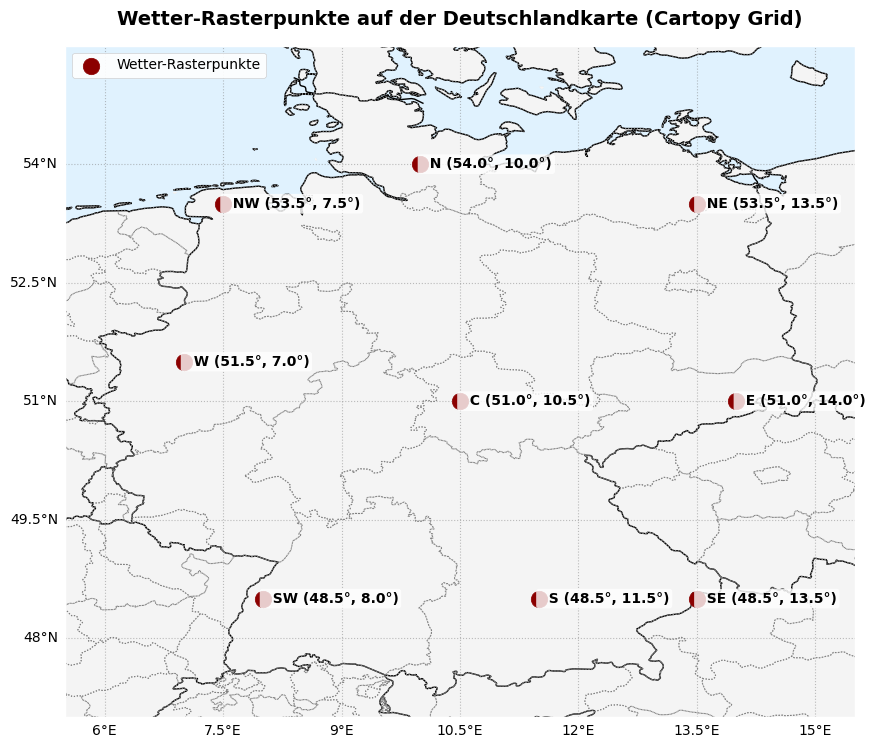

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Raster-Daten holen
grid_points = get_grid_coordinates()
grid_df = pd.DataFrame.from_dict(grid_points, orient='index', columns=['lat', 'lon'])

# 2. Plot mit Cartopy-Projektion (PlateCarree)
fig = plt.figure(figsize=(9, 11))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

# Kartenausschnitt auf Deutschland festlegen
ax.set_extent([5.5, 15.5, 47.0, 55.5], crs=ccrs.PlateCarree())

# 3. Hintergrund-Features hinzufügen (Landmasse, Ozeane, Grenzen, Bundesländer)
ax.add_feature(cfeature.LAND, facecolor='#f4f4f4')
ax.add_feature(cfeature.OCEAN, facecolor='#e0f2fe')
ax.add_feature(cfeature.COASTLINE, linewidth=1.0, edgecolor='black')
ax.add_feature(cfeature.BORDERS, linestyle='-', linewidth=1.0, edgecolor='black')
ax.add_feature(cfeature.STATES.with_scale('10m'), linestyle=':', linewidth=0.8, edgecolor='gray')

# 4. Rasterpunkte plotten (transform=ccrs.PlateCarree() ist entscheidend!)
ax.scatter(
    grid_df['lon'], grid_df['lat'], 
    color='darkred', s=140, zorder=5, marker='o', 
    transform=ccrs.PlateCarree(), label='Wetter-Rasterpunkte'
)

# 5. Beschriftung der Punkte mit weißen Text-Boxen
for name, row in grid_df.iterrows():
    ax.annotate(
        f"  {name} ({row['lat']}°, {row['lon']}°)", 
        (row['lon'], row['lat']), 
        fontsize=10, fontweight='bold', color='black',
        ha='left', va='center', zorder=6,
        transform=ccrs.PlateCarree(),
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none')
    )

# Dezent gestrichelte Rasterlinien
gl = ax.gridlines(draw_labels=True, linestyle=':', alpha=0.5, color='gray')
gl.top_labels = False
gl.right_labels = False

ax.set_title("Wetter-Rasterpunkte auf der Deutschlandkarte (Cartopy Grid)", fontsize=14, pad=15, fontweight='bold')
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

## Data Availability & API-Abgleich

=== DATA AVAILABILITY & API COVERAGE REPORT ===
Angefragter Zeitraum (API-Soll): 2019-01-01 bis 2024-12-31
Erwartete Datenpunkte (Stunden): 52,608
Tatsächlich vorhanden (Ist):      52,602
Gesamte Abdeckung (Coverage):     99.99%

Summary der Datenabdeckung nach Quellen:
                  Requested  Available  Coverage (%)
Source                                              
Open-Meteo API      52608.0    52602.0         99.99
SMARD / OPSD API    52608.0    52602.0         99.99


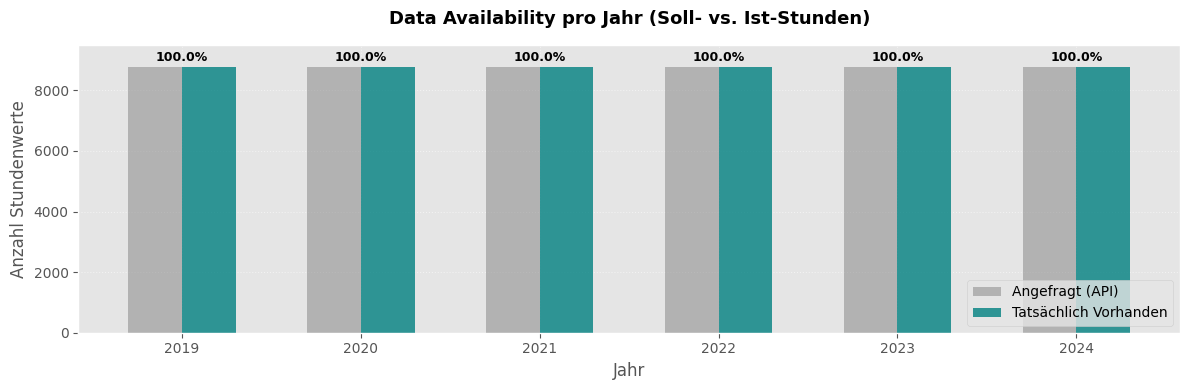

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Datumsvariablen direkt aus der Pipeline importieren
from data_pipeline import START_DATE, END_DATE

print("=== DATA AVAILABILITY & API COVERAGE REPORT ===")

# Definiere den angefragten Soll-Zeitraum (Soll-Matrix)
req_start = START_DATE
req_end = f"{END_DATE} 23:00:00"
requested_range = pd.date_range(start=req_start, end=req_end, freq='h', tz='UTC')
total_requested_hours = len(requested_range)

# 2. Vorhandene Daten im Datensatz (Ist-Matrix)
actual_range = df_raw.index
total_actual_hours = len(actual_range)
coverage_pct = (total_actual_hours / total_requested_hours) * 100

print(f"Angefragter Zeitraum (API-Soll): {req_start} bis {END_DATE}")
print(f"Erwartete Datenpunkte (Stunden): {total_requested_hours:,}")
print(f"Tatsächlich vorhanden (Ist):      {total_actual_hours:,}")
print(f"Gesamte Abdeckung (Coverage):     {coverage_pct:.2f}%\n")

# 3. Detaillierte Analyse pro Spalte / Feature-Gruppe
columns_info = []

# Wetter-Features (9 Punkte)
for name in grid_points.keys():
    w_cols = [c for c in df_raw.columns if c.endswith(f"_{name}")]
    for col in w_cols:
        valid_cnt = df_raw[col].notnull().sum()
        columns_info.append({
            'Source': 'Open-Meteo API',
            'Feature': col,
            'Requested': total_requested_hours,
            'Available': valid_cnt,
            'Coverage (%)': (valid_cnt / total_requested_hours) * 100
        })

# Energie-Features (SMARD / OPSD)
energy_cols = ['generation_solar_mw', 'generation_wind_mw', 'capacity_solar_mw', 'capacity_wind_mw']
for col in energy_cols:
    if col in df_raw.columns:
        valid_cnt = df_raw[col].notnull().sum()
        columns_info.append({
            'Source': 'SMARD / OPSD API',
            'Feature': col,
            'Requested': total_requested_hours,
            'Available': valid_cnt,
            'Coverage (%)': (valid_cnt / total_requested_hours) * 100
        })

df_coverage = pd.DataFrame(columns_info)

# Tabellarische Übersicht der wichtigsten Gruppen anzeigen
print("Summary der Datenabdeckung nach Quellen:")
print(df_coverage.groupby('Source')[['Requested', 'Available', 'Coverage (%)']].mean().round(2))

# 4. Visualisierung der Verfügbarkeit über die Jahre (Jahres-Heatmap/Balken)
years = requested_range.year.unique()
yearly_stats = []

for year in years:
    req_y = (requested_range.year == year).sum()
    act_y = (df_raw.index.year == year).sum()
    yearly_stats.append({
        'Year': year,
        'Requested': req_y,
        'Available': act_y,
        'Coverage (%)': (act_y / req_y) * 100 if req_y > 0 else 0
    })

df_yearly = pd.DataFrame(yearly_stats)

# Plot mit Matplotlib
fig, ax = plt.subplots(figsize=(12, 4))
bars1 = ax.bar(df_yearly['Year'] - 0.15, df_yearly['Requested'], width=0.3, label='Angefragt (API)', color='gray', alpha=0.5)
bars2 = ax.bar(df_yearly['Year'] + 0.15, df_yearly['Available'], width=0.3, label='Tatsächlich Vorhanden', color='teal', alpha=0.8)

# Prozent-Label über die Balken schreiben
for i, row in df_yearly.iterrows():
    ax.text(row['Year'], max(row['Requested'], row['Available']) + 100, 
            f"{row['Coverage (%)']:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title("Data Availability pro Jahr (Soll- vs. Ist-Stunden)", fontsize=13, pad=15, fontweight='bold')
ax.set_ylabel("Anzahl Stundenwerte")
ax.set_xlabel("Jahr")
ax.set_xticks(years)
ax.set_ylim(0, 9500)
ax.legend(loc='lower right', frameon=True)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## 4 Beispiel-Monate (Jan, Apr, Jul, Okt) – Produktion & Wetter

Visualisiere Beispielsdaten für das Jahr: 2024


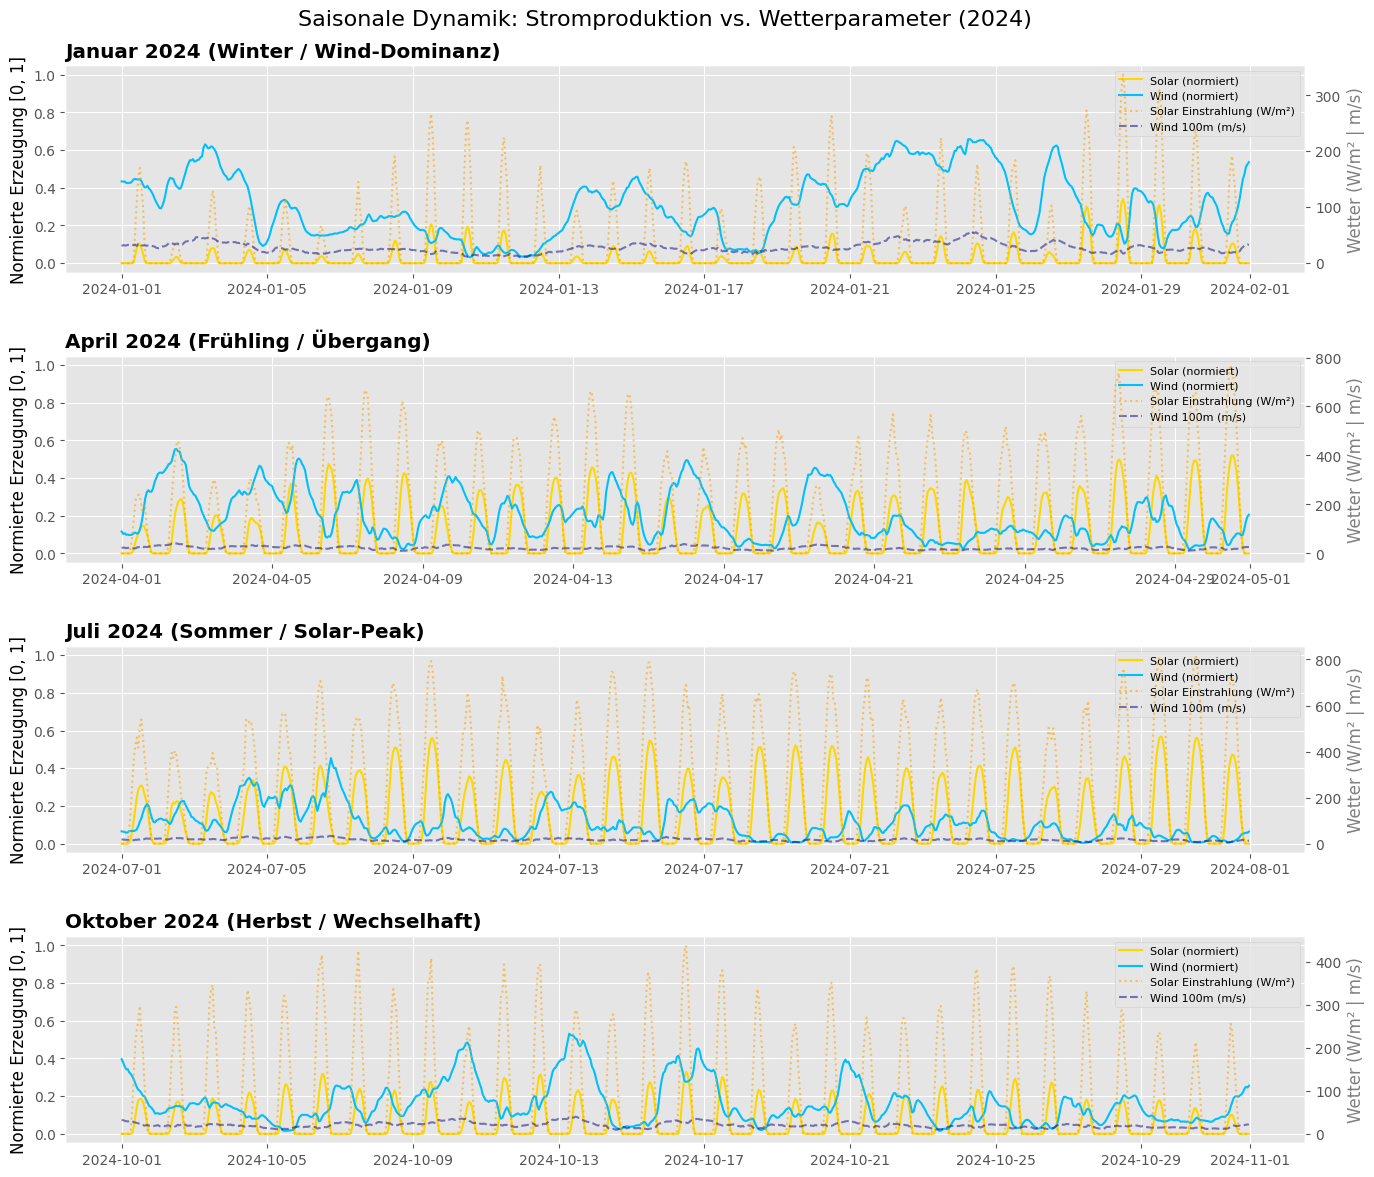

In [7]:
# Dynamisch das letzte verfügbare Jahr ermitteln
last_year = df_raw.index.year.max()
print(f"Visualisiere Beispielsdaten für das Jahr: {last_year}")

months = [
    (f'{last_year}-01', f'Januar {last_year} (Winter / Wind-Dominanz)'),
    (f'{last_year}-04', f'April {last_year} (Frühling / Übergang)'),
    (f'{last_year}-07', f'Juli {last_year} (Sommer / Solar-Peak)'),
    (f'{last_year}-10', f'Oktober {last_year} (Herbst / Wechselhaft)')
]

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=False)
fig.subplots_adjust(hspace=0.4)

for i, (month_str, title) in enumerate(months):
    # Slicing über boolean Maske (funktioniert immer unabhängig von Zeitzonen)
    mask = df_raw.index.strftime('%Y-%m') == month_str
    df_month = df_raw[mask]
    
    if len(df_month) == 0:
        continue
        
    ax1 = axes[i]
    
    # Stromproduktion (Normiert 0-1) auf primärer Y-Achse
    line1 = ax1.plot(df_month.index, df_month['target_solar_norm'], color='gold', linewidth=1.5, label='Solar (normiert)')
    line2 = ax1.plot(df_month.index, df_month['target_wind_norm'], color='deepskyblue', linewidth=1.5, label='Wind (normiert)')
    ax1.set_ylabel("Normierte Erzeugung [0, 1]", color='black')
    ax1.set_ylim(-0.05, 1.05)
    
    # Sekundäre Y-Achse für Wetter
    ax2 = ax1.twinx()
    avg_solar_rad = df_month[[f'surface_solar_radiation_{k}' for k in grid_points]].mean(axis=1)
    avg_wind_speed = df_month[[f'wind_speed_100m_{k}' for k in grid_points]].mean(axis=1)
    
    line3 = ax2.plot(df_month.index, avg_solar_rad, color='orange', linestyle=':', alpha=0.6, label='Solar Einstrahlung (W/m²)')
    line4 = ax2.plot(df_month.index, avg_wind_speed, color='navy', linestyle='--', alpha=0.5, label='Wind 100m (m/s)')
    ax2.set_ylabel("Wetter (W/m² | m/s)", color='gray')
    ax2.grid(False)
    
    # Legende
    lines = line1 + line2 + line3 + line4
    labels_legend = [l.get_label() for l in lines]
    ax1.legend(lines, labels_legend, loc='upper right', fontsize=8, frameon=True)
    ax1.set_title(title, fontweight='bold', loc='left')

plt.suptitle(f"Saisonale Dynamik: Stromproduktion vs. Wetterparameter ({last_year})", fontsize=16, y=0.92)
plt.show()

## Korrelationsmatrix & Scatter-Plots

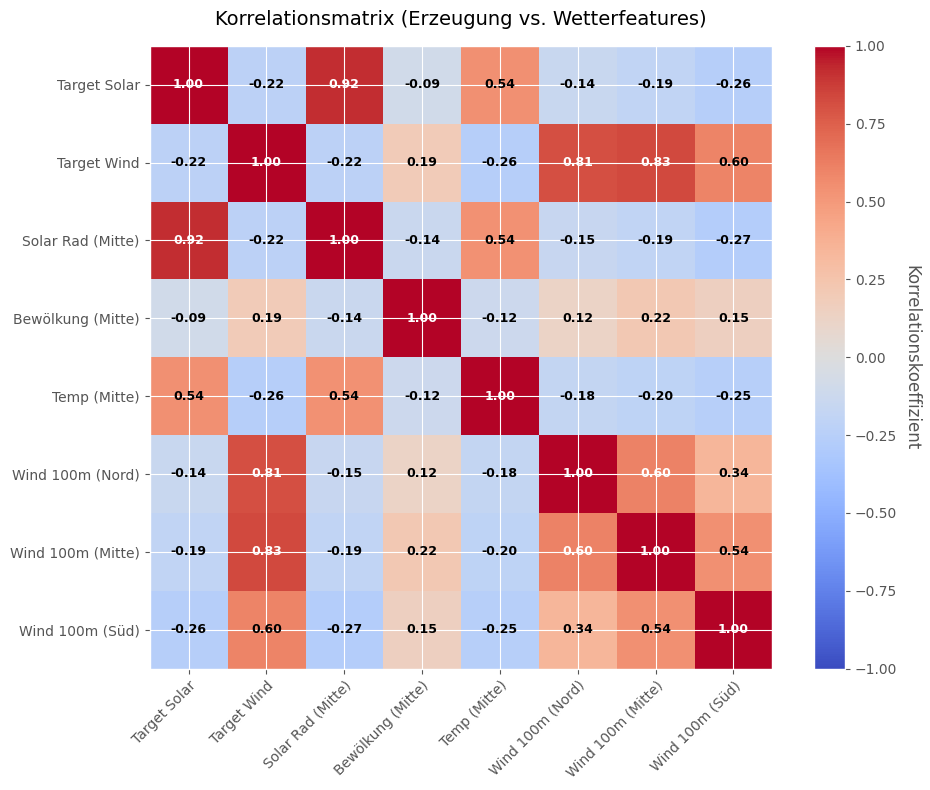

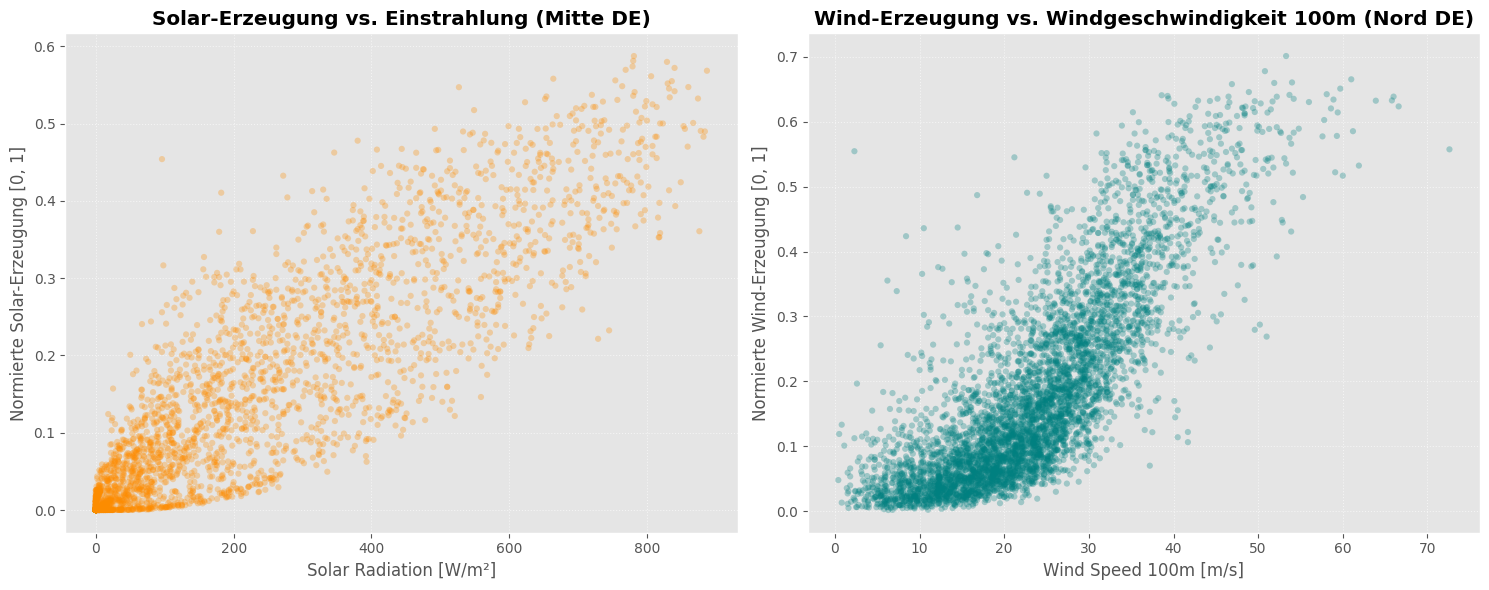

In [8]:
# 1. Spaltenauswahl für Korrelation
corr_cols = [
    'target_solar_norm', 'target_wind_norm',
    'surface_solar_radiation_C', 'cloud_cover_C', 'temperature_2m_C',
    'wind_speed_100m_N', 'wind_speed_100m_C', 'wind_speed_100m_S'
]

labels = [
    'Target Solar', 'Target Wind',
    'Solar Rad (Mitte)', 'Bewölkung (Mitte)', 'Temp (Mitte)',
    'Wind 100m (Nord)', 'Wind 100m (Mitte)', 'Wind 100m (Süd)'
]

corr_df = df_raw[corr_cols].corr()
corr_matrix = corr_df.values

# --- 1. Korrelationsmatrix mit Matplotlib (plt.imshow) ---
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

# Colorbar hinzufügen
cbar = ax.figure.colorbar(im, ax=ax)
cbar.ax.set_ylabel("Korrelationskoeffizient", rotation=-90, va="bottom")

# Achsenbeschriftungen
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticklabels(labels)

# Text-Werte in die Kästchen schreiben
for i in range(len(labels)):
    for j in range(len(labels)):
        text_color = "white" if abs(corr_matrix[i, j]) > 0.6 else "black"
        ax.text(j, i, f"{corr_matrix[i, j]:.2f}",
                ha="center", va="center", color=text_color, fontweight='bold', fontsize=9)

ax.set_title("Korrelationsmatrix (Erzeugung vs. Wetterfeatures)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# --- 2. Scatter-Plots mit Matplotlib (plt.scatter) ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Stichprobe für performantes Plotten ziehen
sample_df = df_raw.sample(5000, random_state=42)

# Solar vs. Einstrahlung
axes[0].scatter(
    sample_df['surface_solar_radiation_C'], 
    sample_df['target_solar_norm'], 
    alpha=0.3, color='darkorange', edgecolors='none', s=20
)
axes[0].set_title("Solar-Erzeugung vs. Einstrahlung (Mitte DE)", fontweight='bold')
axes[0].set_xlabel("Solar Radiation [W/m²]")
axes[0].set_ylabel("Normierte Solar-Erzeugung [0, 1]")
axes[0].grid(True, linestyle=':', alpha=0.6)

# Wind vs. Windgeschwindigkeit Nord
axes[1].scatter(
    sample_df['wind_speed_100m_N'], 
    sample_df['target_wind_norm'], 
    alpha=0.3, color='teal', edgecolors='none', s=20
)
axes[1].set_title("Wind-Erzeugung vs. Windgeschwindigkeit 100m (Nord DE)", fontweight='bold')
axes[1].set_xlabel("Wind Speed 100m [m/s]")
axes[1].set_ylabel("Normierte Wind-Erzeugung [0, 1]")
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Autokorrelation & Lags

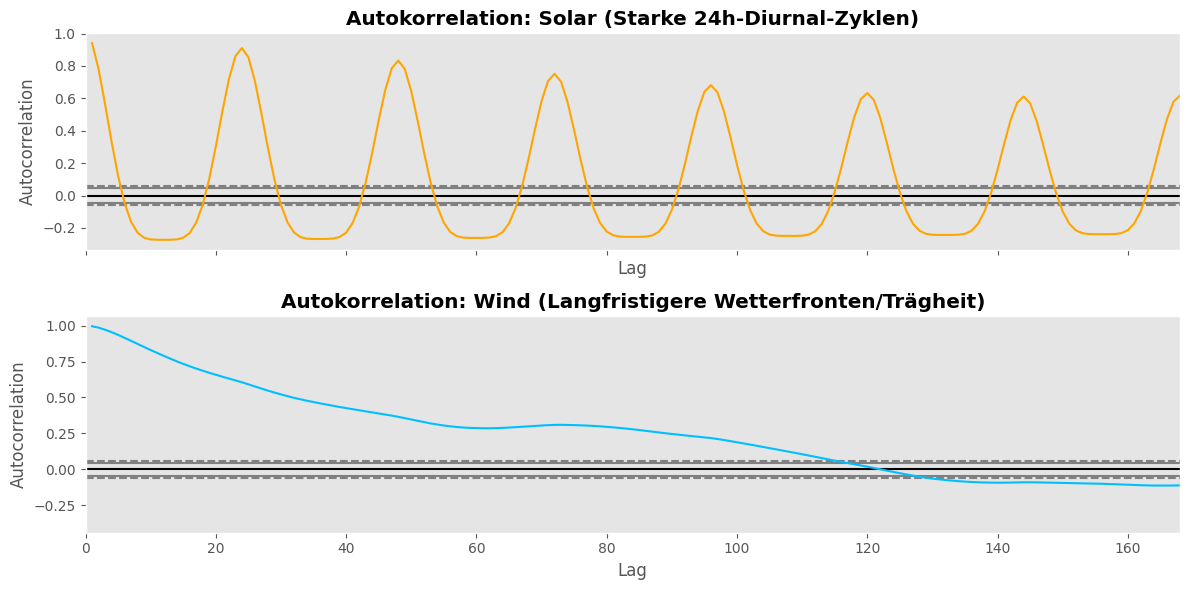

In [9]:
from pandas.plotting import autocorrelation_plot

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Autokorrelation der letzten 168h (1 Woche)
pd.plotting.autocorrelation_plot(train_df['target_solar_norm'].iloc[:2000], ax=ax1, color='orange')
ax1.set_title("Autokorrelation: Solar (Starke 24h-Diurnal-Zyklen)", fontweight='bold')
ax1.set_xlim(0, 168) # 7 Tage

pd.plotting.autocorrelation_plot(train_df['target_wind_norm'].iloc[:2000], ax=ax2, color='deepskyblue')
ax2.set_title("Autokorrelation: Wind (Langfristigere Wetterfronten/Trägheit)", fontweight='bold')
ax2.set_xlim(0, 168)

plt.tight_layout()
plt.show()

## Tages- und Wochenprofile (Diurnal & Weekly Cycles)

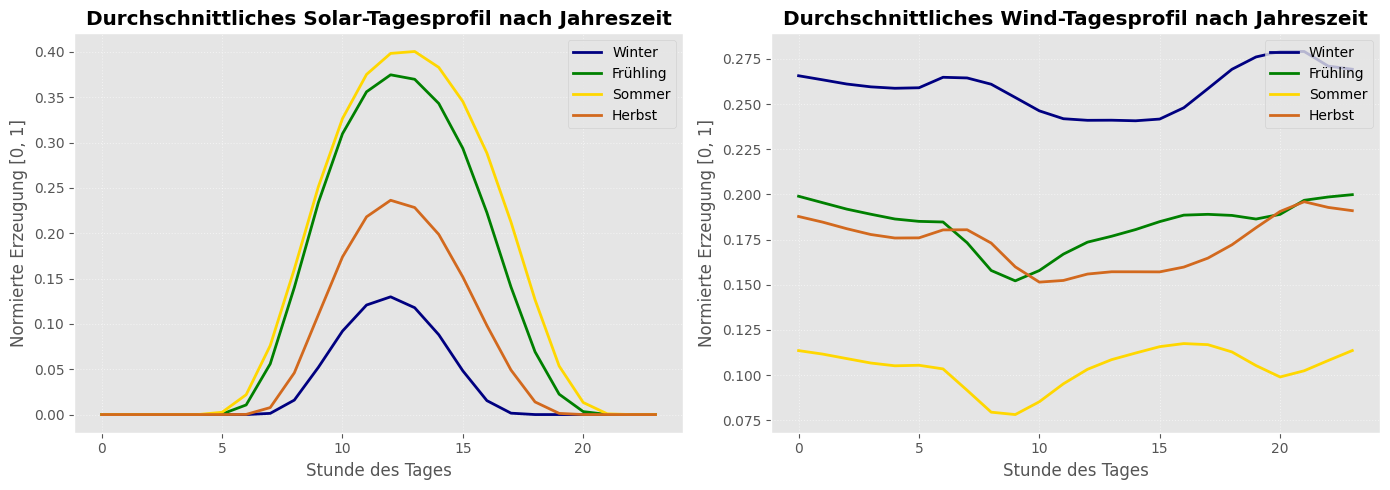

In [10]:
# Aggregation nach Stunde und Jahreszeit
train_df['hour'] = train_df.index.hour
train_df['season'] = train_df.index.month % 12 // 3 # 0: Winter, 1: Frühling, 2: Sommer, 3: Herbst

seasons = {0: ('Winter', 'navy'), 1: ('Frühling', 'green'), 2: ('Sommer', 'gold'), 3: ('Herbst', 'chocolate')}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for s_idx, (s_name, color) in seasons.items():
    subset = train_df[train_df['season'] == s_idx]
    
    # Solar-Tagesprofil
    solar_profile = subset.groupby('hour')['target_solar_norm'].mean()
    ax1.plot(solar_profile.index, solar_profile.values, label=s_name, color=color, linewidth=2)
    
    # Wind-Tagesprofil
    wind_profile = subset.groupby('hour')['target_wind_norm'].mean()
    ax2.plot(wind_profile.index, wind_profile.values, label=s_name, color=color, linewidth=2)

ax1.set_title("Durchschnittliches Solar-Tagesprofil nach Jahreszeit", fontweight='bold')
ax1.set_xlabel("Stunde des Tages")
ax1.set_ylabel("Normierte Erzeugung [0, 1]")
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend()

ax2.set_title("Durchschnittliches Wind-Tagesprofil nach Jahreszeit", fontweight='bold')
ax2.set_xlabel("Stunde des Tages")
ax2.set_ylabel("Normierte Erzeugung [0, 1]")
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

## Zielwert-Verteilungen (Histograms & KDE Approximation)

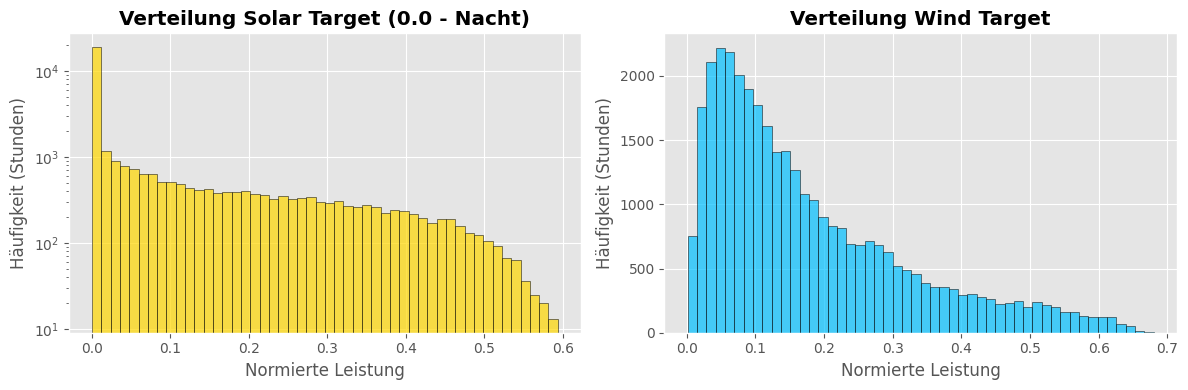

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Histograms
ax[0].hist(train_df['target_solar_norm'], bins=50, color='gold', edgecolor='black', alpha=0.7)
ax[0].set_title("Verteilung Solar Target (0.0 - Nacht)", fontweight='bold')
ax[0].set_xlabel("Normierte Leistung")
ax[0].set_ylabel("Häufigkeit (Stunden)")
ax[0].set_yscale('log') # Log-Skala wegen hoher 0-Werte

ax[1].hist(train_df['target_wind_norm'], bins=50, color='deepskyblue', edgecolor='black', alpha=0.7)
ax[1].set_title("Verteilung Wind Target", fontweight='bold')
ax[1].set_xlabel("Normierte Leistung")
ax[1].set_ylabel("Häufigkeit (Stunden)")

plt.tight_layout()
plt.show()

## Extremwert- / Dunkelflauten-Analyse

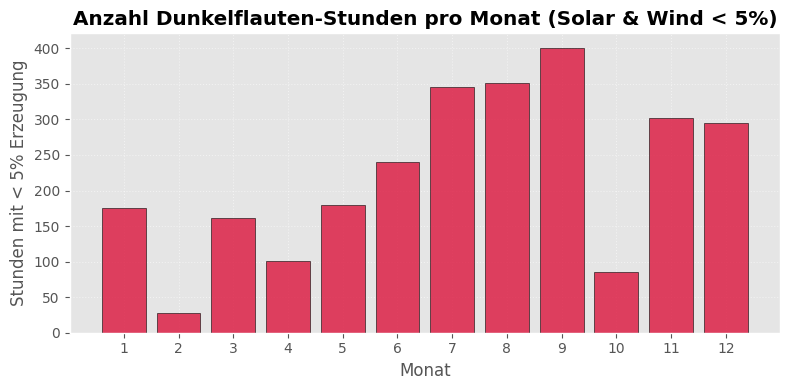

In [12]:
# Dunkelflauten-Bedingung: Beide Erzeugungen < 5% der Nennleistung
dunkelflaute_mask = (train_df['target_solar_norm'] < 0.05) & (train_df['target_wind_norm'] < 0.05)
dunkelflaute_hours = train_df[dunkelflaute_mask]

# Aufschlüsselung nach Monaten
df_dunkel_monthly = dunkelflaute_hours.groupby(dunkelflaute_hours.index.month).size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df_dunkel_monthly.index, df_dunkel_monthly.values, color='crimson', alpha=0.8, edgecolor='black')
ax.set_title("Anzahl Dunkelflauten-Stunden pro Monat (Solar & Wind < 5%)", fontweight='bold')
ax.set_xlabel("Monat")
ax.set_ylabel("Stunden mit < 5% Erzeugung")
ax.set_xticks(range(1, 13))
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()